In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from keras.callbacks import EarlyStopping , ReduceLROnPlateau

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
data = pd.read_csv(r"/content/spam_ham_dataset.csv")
data.head(3)

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0


In [ ]:
data.shape

(5171, 4)

In [ ]:
data.isnull().any()

,0
Unnamed: 0,False
label,False
text,False
label_num,False


In [ ]:
data.isnull().sum()

,0
Unnamed: 0,0
label,0
text,0
label_num,0


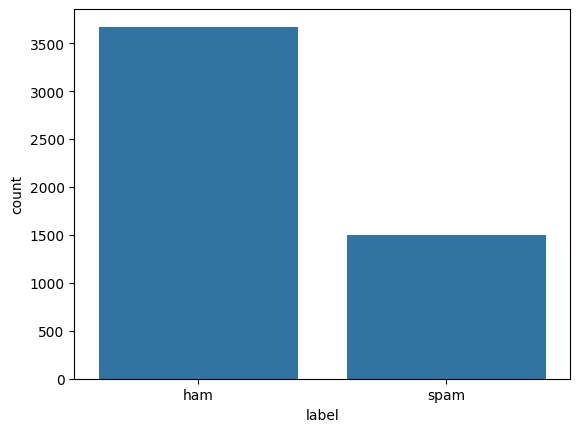

In [ ]:
sns.countplot(x = "label" , data=data)
plt.show()

In [ ]:
ham_msg = data[data["label"] == "ham"]
spam_msg = data[data["label"] == 'spam']
ham_msg_balance = ham_msg.sample(n=len(spam_msg), random_state = 42)
balance_data = pd.concat([ham_msg_balance , spam_msg]).reset_index(drop = True)

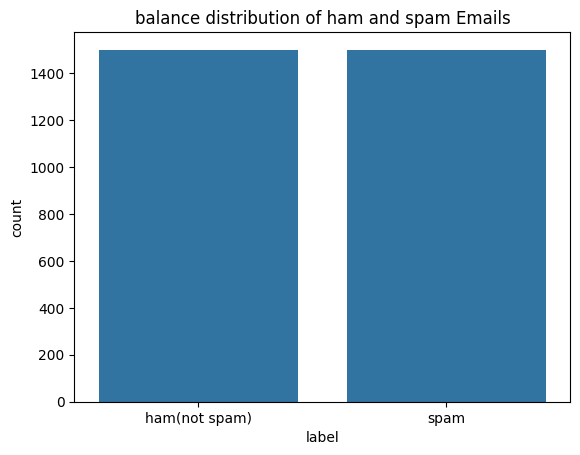

In [ ]:
sns.countplot(x = "label" , data = balance_data)
plt.title("balance distribution of ham and spam Emails")
plt.xticks(ticks=[0,1], labels = ["ham(not spam)" , "spam"])
plt.show()

In [ ]:
balance_data["text"] = balance_data["text"].str.replace("subject", '')
balance_data.head(3)

,Unnamed: 0,label,text,label_num
0,3444,ham,Subject: conoco - big cowboy\r\ndarren :\r\ni ...,0
1,2982,ham,Subject: feb 01 prod : sale to teco gas proces...,0
2,2711,ham,Subject: california energy crisis\r\ncaliforni...,0


In [ ]:
punctuation_list = string.punctuation
def remove_punctuations(text):
  temp = str.maketrans('','', punctuation_list)
  return text.translate(temp)

balance_data["text"] = balance_data["text"].apply(lambda x: remove_punctuations(x))
balance_data.head(4)

,Unnamed: 0,label,text,label_num
0,3444,ham,Subject conoco big cowboy\r\ndarren \r\ni m ...,0
1,2982,ham,Subject feb 01 prod sale to teco gas processi...,0
2,2711,ham,Subject california energy crisis\r\ncalifornia...,0
3,3116,ham,Subject re nom actual volume for april 23 rd...,0


In [ ]:
def remove_stopwords(text):
  stop_words = stopwords.words("english")
  imp_words = []
  for word in str(text).split():
    word = word.lower()
    if word not in stop_words:
      imp_words.append(word)
  output = " " .join(imp_words)
  return output

balance_data["text"] = balance_data["text"].apply(lambda x: remove_stopwords(x))
balance_data.head(4)

,Unnamed: 0,label,text,label_num
0,3444,ham,subject conoco big cowboy darren sure help kno...,0
1,2982,ham,subject feb 01 prod sale teco gas processing s...,0
2,2711,ham,subject california energy crisis california  ...,0
3,3116,ham,subject nom actual volume april 23 rd agree ei...,0


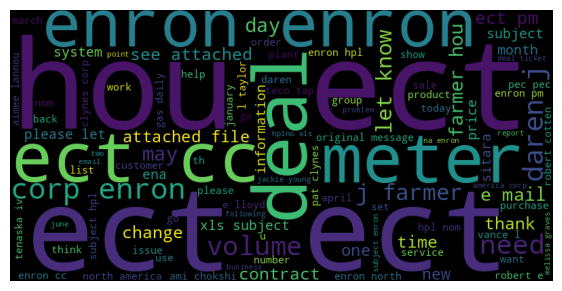

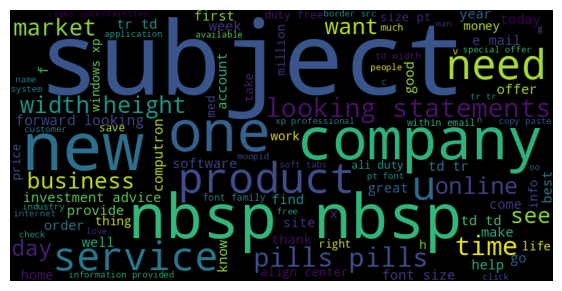

In [ ]:
def plot_word_cloud(data , typ):
  email_corpus = " " .join(data["text"])
  wc = WordCloud(background_color= 'black' , max_words=100, width=800, height = 400).generate(email_corpus)
  plt.figure(figsize=(7,7))
  plt.imshow(wc)
  plt.axis("off")
  plt.show()


plot_word_cloud(balance_data[balance_data['label'] == 'ham'], typ='Non-Spam')
plot_word_cloud(balance_data[balance_data['label'] == 'spam'], typ='Spam')

In [ ]:
train_x , test_x , train_y , test_y = train_test_split(balance_data["text"], balance_data["label"], test_size=0.2, random_state=42)

In [ ]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_x)


In [ ]:
train_sequence = tokenizer.texts_to_sequences(train_x)
test_sequence = tokenizer.texts_to_sequences(test_x)

In [ ]:
max_len = 100

train_sequence = pad_sequences(train_sequence, maxlen=max_len, padding = "post" , truncating="post")
test_sequence = pad_sequences(test_sequence, maxlen=max_len, padding = "post", truncating="post")

In [ ]:
train_y = (train_y == "spam").astype(int)
test_y = (test_y == "spam").astype(int)

In [ ]:
# model = tf.keras.models.sequencial([
#     tf.keras.layers.Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=32,input_length=max_lan),
#     tf.keras.layers.LSTM(64, return_sequences= True)
# ])

In [ ]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=32, input_length=max_len),
    tf.keras.layers.LSTM(16),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')  # Output layer
])

model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
es = EarlyStopping(patience=3, monitor='val_accuracy', restore_best_weights=True)
lr = ReduceLROnPlateau(patience=2, monitor='val_loss', factor=0.5, verbose=0)

history = model.fit(
    train_sequence, train_y,
    validation_data=(test_sequence, test_y),
    epochs=20,
    batch_size=32,
    callbacks=[lr, es]
)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 9s 77ms/step - accuracy: 0.9227 - loss: 0.4784 - val_accuracy: 0.5250 - val_loss: 1.9799 - learning_rate: 0.0010
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 1.0000 - loss: 0.0107 - val_accuracy: 0.5250 - val_loss: 2.9156 - learning_rate: 0.0010
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.5250 - val_loss: 3.4841 - learning_rate: 0.0010
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 1.0000 - loss: 7.1130e-04 - val_accuracy: 0.5250 - val_loss: 3.6809 - learning_rate: 5.0000e-04


In [ ]:
test_loss , test_accuracy = model.evaluate(test_sequence, test_y)
print("Test loss:", test_loss)
print("rest accuracy:" , test_accuracy)

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5179 - loss: 2.0155
Test loss: 1.9799004793167114
rest accuracy: 0.5249999761581421


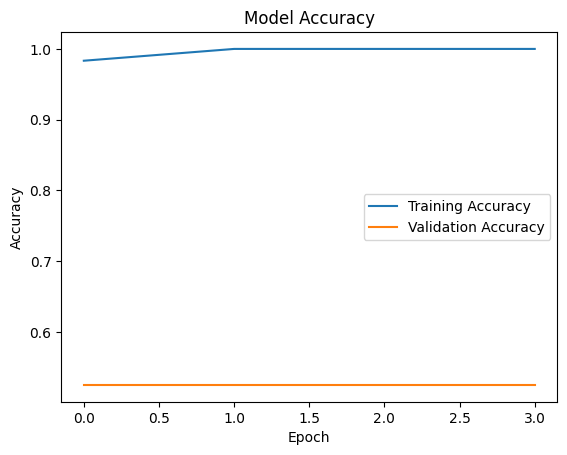

In [ ]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.show()